# **1. LSTM**

LSTM(Long Short-Term Memory)은 **RNN의 장기 의존성 문제를 해결하기 위해 고안된 모델**이다. LSTM은 셀 상태(cell state)와 3개의 게이트(입력 게이트, 출력 게이트, 망각 게이트)를 사용하여 중요한 정보를 오랫동안 저장하고 불필요한 정보를 제거하는 구조를 갖추고 있다. 망각 게이트는 이전 셀 상태에서 필요 없는 정보를 삭제하고, 입력 게이트는 새로운 정보를 저장하며, 출력 게이트는 최종 출력을 결정한다. 이러한 구조 덕분에 LSTM은 장기 시퀀스를 다루는 자연어 처리, 음성 인식, 시계열 예측 등의 다양한 분야에서 효과적으로 사용된다. 하지만 구조가 복잡하여 계산량이 많고, 학습 시간이 오래 걸린다는 단점이 있다.

![LSTM](./images/LSTM1.png)

![LSTM2](./images/LSTM2.png)

### RNN이 오래된 정보를 잊어버리는 이유
RNN은 학습할 때 역전파(Backpropagation)를 사용한다. 순차 데이터에서는 여러 시점을 거슬러 올라가면서 미분값을 전달해야 한다.
```
t=1 < t=2 < t=3 < t=4 < ...
0.5 * 0.5 * 0.5 * 0.5 ...
이 과정에서 작은 값이 계속 곱해지므로 값이 매우 작아짐
```
> 결국 앞쪽 시점까지 도착했을때, gradient가 거의 0에 가까워질 수 있다.
> 0일때 기울기 소실 문제라고 부른다.
> 그래서 일반적인 RNN은 멀리 떨어진 정보 사이의 관계를 학습하는 것이 어렵다.

### LSTM의 핵심 아이디어
```
새로운 데이터 입력 > 과거 기억 확인 > 필요 없는 기억 삭제 > 새로운 중요한 정보 추가 > 장기 기억 업데이트 > 현재 필요한 정보 출력 > 다음 데이터 처리
```
1. Forget Gate: 무엇을 잊을 것인가?
2. Input Gate: 무엇을 새로 기억할 것인가?
3. Output Gate: 무엇을 밖으로 출력할 것인가?
4. Cell State: 실제 장기 기억

### Individual Household Electric Power Consumption 데이터셋
한 가정에서 약 4년 동안 1분 간격으로 측정한 전력 사용량 데이터이며 약 207만 개 관측치와 9개 특성을 가지고 있다.
- [다운로드](https://archive.ics.uci.edu/dataset/235/individual%2Bhousehold%2Belectric%2Bpower%2Bconsumption?utm_source=chatgpt.com)

In [69]:
import random
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

warnings.filterwarnings("ignore")

In [27]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [28]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [29]:
DATA_PATH = "./data/household_power_consumption.txt"
df = pd.read_csv(DATA_PATH, sep=';', na_values='?', low_memory=False)
print(df.shape)
df.head()

(2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


- `Date` : 날짜
- `Time` : 시간
- `Global_active_power` : 전체 유효전력
- `Global_reactive_power` : 무효전력
- `Voltage` : 전압
- `Global_intensity` : 전류 세기
- `Sub_metering_1~3` : 구역별 전력 사용량

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB


In [31]:
df.isna().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [32]:
df['datetime'] = pd.to_datetime(df['Date'] + " " + df['Time'],
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")

In [33]:
df = df.sort_values('datetime')
df = df.set_index('datetime')
df

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
...,...,...,...,...,...,...,...,...,...
2010-11-26 20:58:00,26/11/2010,20:58:00,0.946,0.000,240.43,4.0,0.0,0.0,0.0
2010-11-26 20:59:00,26/11/2010,20:59:00,0.944,0.000,240.00,4.0,0.0,0.0,0.0
2010-11-26 21:00:00,26/11/2010,21:00:00,0.938,0.000,239.82,3.8,0.0,0.0,0.0


In [34]:
power = df[['Global_active_power']].copy()
power["Global_active_power"] = pd.to_numeric(
    power["Global_active_power"], errors="coerce"
)
power = power.dropna()

print(power.shape)

(2049280, 1)


In [35]:
power.head()

,Global_active_power
datetime,
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


In [36]:
# 원본 데이터는 2049280행으로 매우 큼
# LSTM 실습에서는 1시간 평균으로 줄여 학습을 가볍게 만듦
# resample('1h').mean(): 같은 한 시간 안에 존재하는 1분 단위 값들의 평균을 계산함
hourly = power.resample('1h').mean()
hourly = hourly.dropna()

print(hourly.shape)

(34168, 1)


In [37]:
hourly.head()

,Global_active_power
datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


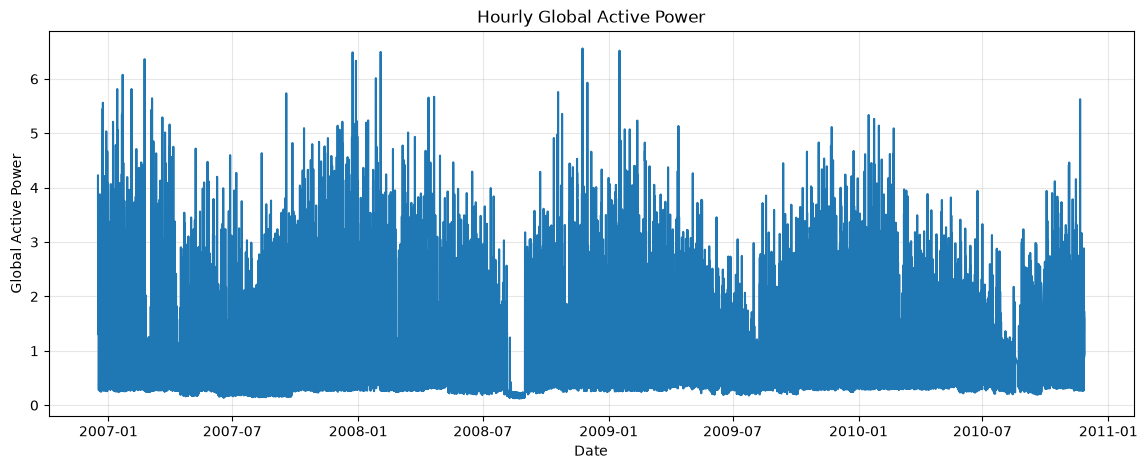

In [38]:
plt.figure(figsize=(14, 5))
plt.plot(hourly.index, hourly["Global_active_power"])
plt.title("Hourly Global Active Power")
plt.xlabel("Date")
plt.ylabel("Global Active Power")
plt.grid(alpha=0.3)
plt.show()

In [39]:
values = hourly['Global_active_power'].values.reshape(-1, 1)

In [40]:
n = len(values)
n

34168

In [50]:
train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("전체:", n)
print("Train:", train_end)
print("Val:", val_end - train_end)
print("Test:", n - val_end)

전체: 34168
Train: 23917
Val: 5125
Test: 5126


In [44]:
# Scaler는 반드시 train 데이터에만 fit 해야함
# 전체 데이터에 fit하면 미래 데이터의 평균과 표준편차가 학습과정에 들어가는 데이터 누수가 발생할 수 있음
scaler = StandardScaler()
scaler.fit(values[:train_end])
scaler_values = scaler.transform(values).astype(np.float32)

In [45]:
SEQ_LENGTH = 24

def make_sequences(data, seq_length):
    X = []
    y = []
    target_indices = []

    for i in range(seq_length, len(data)):
        X.append(data[i-seq_length:i])
        y.append(data[i])
        target_indices.append(i)

    return(np.array(X, dtype=np.float32),
           np.array(y, dtype=np.float32),
           np.array(target_indices))

In [ ]:
X, y, indices = make_sequences(scaler_values, SEQ_LENGTH)

print("X:", X.shape)
print("y:", y.shape)

X:  (34144, 24, 1)
y:  (34144, 1)


In [49]:
train_mask = indices < train_end
val_mask = ((indices >= train_end) & (indices < val_end))
test_mask = indices >= val_end

print(train_mask)
print(val_mask)
print(test_mask)

[ True  True  True ... False False False]
[False False False ... False False False]
[False False False ...  True  True  True]


In [51]:
X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print('Train:', X_train.shape, y_train.shape)
print('Val:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)

Train: (23893, 24, 1) (23893, 1)
Val: (5125, 24, 1) (5125, 1)
Test: (5126, 24, 1) (5126, 1)


In [54]:
class PowerDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [55]:
BATCH_SIZE = 64

train_loader = DataLoader(PowerDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(PowerDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(PowerDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

In [57]:
Xb, yb = next(iter(train_loader))

print("X batch:", Xb.shape)
print("y batch:", yb.shape)

X batch: torch.Size([64, 24, 1])
y batch: torch.Size([64, 1])


### LSTM 모델
```
out, (h_n, c_n) = self.lstm(X)
```
- h_n: 마지막 hidden state
- c_n: 마지막 cell state
- out[:, -1, :]을 linear layer에 넣어 다음 한 시간의 전력 사용량을 예측

In [58]:
class PowerLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = out[:, -1, :]
        prediction = self.fc(last_hidden)
        return prediction

In [59]:
model = PowerLSTM().to(DEVICE)
print(model)

PowerLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [60]:
model.eval()

with torch.no_grad():
    sample_x = Xb[:4].to(DEVICE)

    out, (h_n, c_n) = model.lstm(sample_x)

print("입력:", sample_x.shape)
print("out:", out.shape)
print("h_n:", h_n.shape)
print("c_n:", c_n.shape)

입력: torch.Size([4, 24, 1])
out: torch.Size([4, 24, 64])
h_n: torch.Size([2, 4, 64])
c_n: torch.Size([2, 4, 64])


In [61]:
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
MAX_EPOCHS = 50
PATIENCE = 8
CLIP_NORM = 1.0

In [63]:
def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_count = 0
    
    with torch.no_grad():
        for Xb, yb in loader:
            Xb = Xb.to(device)
            yb = yb.to(device)
            pred = model(Xb)
            loss = criterion(pred, yb)
            batch_size = Xb.size(0)
            total_loss += (loss.item() * batch_size)
            total_count += batch_size
    return total_loss / total_count

In [65]:
best_val_loss = float("inf")
best_state = None
wait = 0

train_history = []
val_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for Xb, yb in train_loader:
        Xb = Xb.to(DEVICE)
        yb = yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        pred = model(Xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_NORM)
        optimizer.step()
        batch_size = Xb.size(0)
        train_loss_sum += (loss.item() * batch_size)
        train_count += batch_size

    train_loss = (train_loss_sum / train_count)
    val_loss = evaluate_loss(model, val_loader, criterion, DEVICE)
    train_history.append(train_loss)
    val_history.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.6f} | "
        f"Valid {val_loss:.6f}"
    )

    if wait >= PATIENCE:
        print("Early Stopping")
        break

Epoch 01 | Train 0.537109 | Valid 0.426783
Epoch 02 | Train 0.435080 | Valid 0.407446
Epoch 03 | Train 0.424414 | Valid 0.410834
Epoch 04 | Train 0.420194 | Valid 0.398537
Epoch 05 | Train 0.416145 | Valid 0.390453
Epoch 06 | Train 0.410848 | Valid 0.399586
Epoch 07 | Train 0.408810 | Valid 0.386644
Epoch 08 | Train 0.406216 | Valid 0.388184
Epoch 09 | Train 0.405975 | Valid 0.385082
Epoch 10 | Train 0.402282 | Valid 0.381896
Epoch 11 | Train 0.402629 | Valid 0.383369
Epoch 12 | Train 0.399549 | Valid 0.377822
Epoch 13 | Train 0.397628 | Valid 0.381359
Epoch 14 | Train 0.396846 | Valid 0.382668
Epoch 15 | Train 0.397978 | Valid 0.378397
Epoch 16 | Train 0.394343 | Valid 0.383755
Epoch 17 | Train 0.393133 | Valid 0.379252
Epoch 18 | Train 0.392051 | Valid 0.379318
Epoch 19 | Train 0.391589 | Valid 0.374782
Epoch 20 | Train 0.388576 | Valid 0.375973
Epoch 21 | Train 0.388675 | Valid 0.390338
Epoch 22 | Train 0.388338 | Valid 0.380726
Epoch 23 | Train 0.385939 | Valid 0.378793
Epoch 24 | 

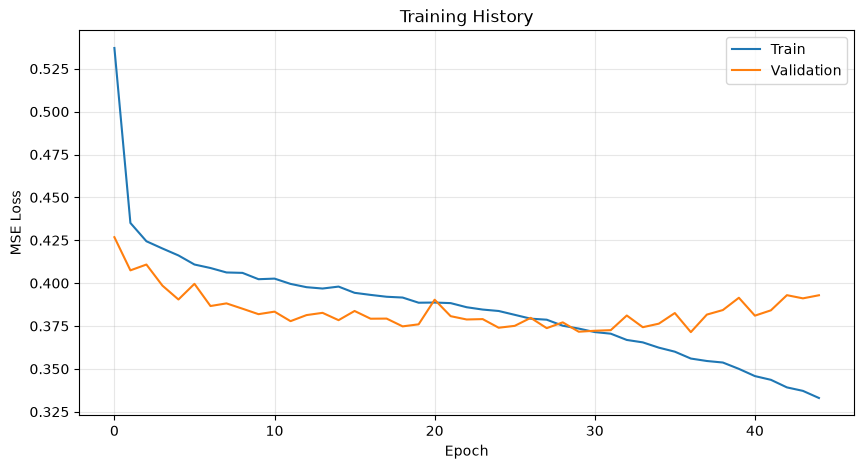

In [66]:
plt.figure(figsize=(10, 5))
plt.plot(train_history, label="Train")
plt.plot(val_history, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [67]:
def predict(model, loader, device):
    model.eval()
    preds = []
    trues = []
    
    with torch.no_grad():
        for Xb, yb in loader:
            Xb = Xb.to(device)
            yb = yb.to(device)
            pred = model(Xb)
            preds.append(pred.cpu().numpy())
            trues.append(yb.cpu().numpy())
    return (np.vstack(preds), np.vstack(trues))

In [68]:
pred_scaled, true_scaled = predict(model, test_loader, DEVICE)
pred = scaler.inverse_transform(pred_scaled).ravel()
true = scaler.inverse_transform(true_scaled).ravel()

In [72]:
rmse = root_mean_squared_error(true, pred)
print(f'RMSE: {rmse:.4f}')

RMSE: 0.4954


In [73]:
test_indices = indices[test_mask]
test_dates = hourly.index[test_indices]
N_VIEW = min(200, len(test_dates))

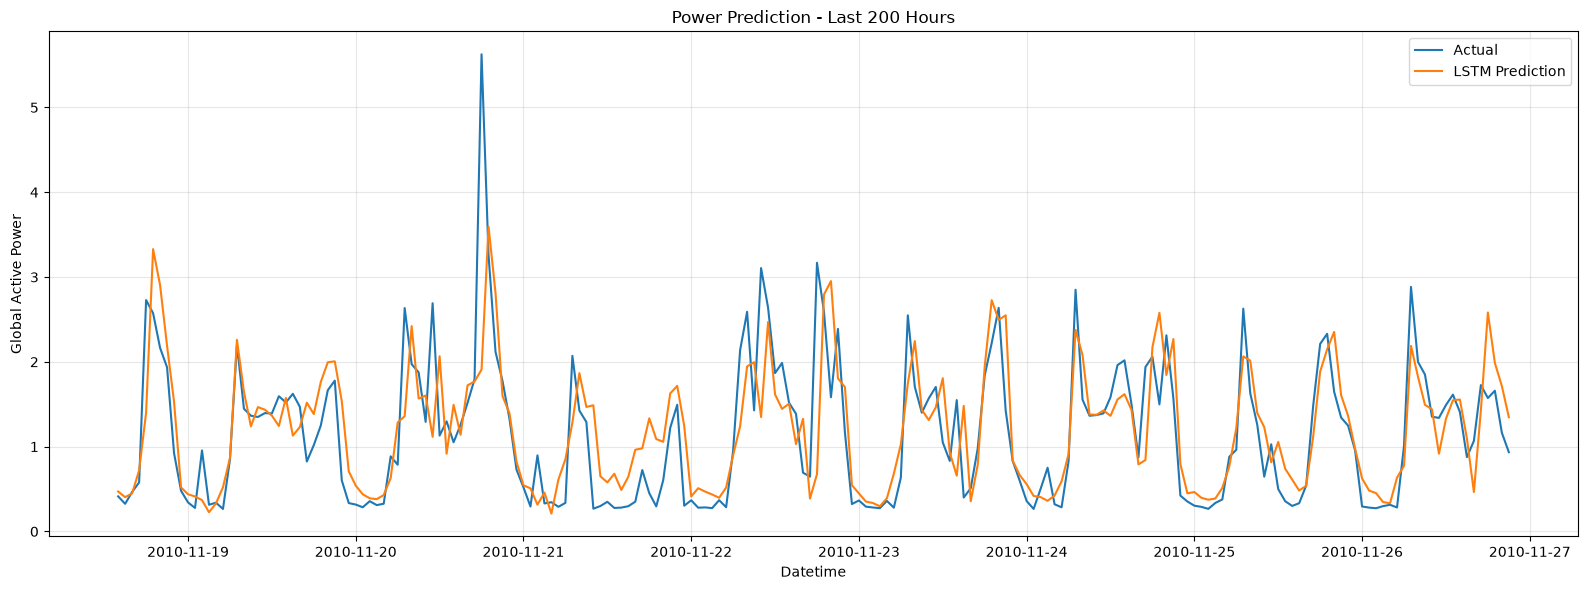

In [74]:
plt.figure(figsize=(16, 6))
plt.plot(
    test_dates[-N_VIEW:],
    true[-N_VIEW:],
    label="Actual"
)
plt.plot(
    test_dates[-N_VIEW:],
    pred[-N_VIEW:],
    label="LSTM Prediction"
)
plt.title(
    f"Power Prediction - Last {N_VIEW} Hours"
)
plt.xlabel("Datetime")
plt.ylabel("Global Active Power")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **2. GRU**

GRU(Gated Recurrent Unit)는 2014년 뉴욕대학교(NYU) 조경현(Kyunghyun Cho) 교수 연구팀이 제안한 RNN의 장기 의존성 문제를 해결하기 위해 개발한 신경망 구조이다. LSTM과 유사한 성능을 가지면서도 더 간단한 구조를 갖고 있어 연산량이 적고 학습 속도가 빠르다. GRU는 업데이트 게이트(Update Gate)와 리셋 게이트(Reset Gate)라는 두 개의 게이트만을 사용하여 정보를 조절하며, LSTM보다 파라미터 수가 적어 적은 데이터셋에서도 효과적으로 학습할 수 있다. 업데이트 게이트는 이전 정보를 얼마나 유지할지 결정하고, 리셋 게이트는 새로운 정보를 반영하기 위해 기존 정보를 얼마나 잊을지 조정한다. 이러한 특성 덕분에 GRU는 텍스트 처리, 음성 인식, 시계열 예측 등에서 LSTM보다 더 빠르고 효율적으로 사용할 수 있지만, 장기 의존성이 중요한 경우 LSTM이 더 나은 성능을 보일 수도 있다.

![GRU](./images/GRU.jpg)

```
LSTM
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
GRU
        self.gru = nn.GRU(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)

LSTM
        out, (h_n, c_n) = self.lstm(x)
GRU
        out, h_n = self.gru(x)
```